# Figure: Transmission Map Histograms

Each row: a recovered transmission map image next to its pixel histogram.
Overlay of the input image histogram (dashed) shows how the TXM distribution
differs from the processed image.

**Requires:** `nb_run.ipynb`

Output: `build/transmission_maps_histograms.png`

In [1]:
%%capture
import os, subprocess, sys

IN_COLAB = "COLAB_GPU" in os.environ or "COLAB_RELEASE_TAG" in os.environ

if IN_COLAB:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive")

    REPO = "/content/drive/MyDrive/Reconstruction"  # <-- repo location on Drive

    os.chdir(f"{REPO}/figures")
else:
    REPO = os.path.abspath("..")

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", REPO])
if REPO not in sys.path:
    sys.path.insert(0, REPO)



[notice] A new release of pip is available: 25.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import sys, os, glob, joblib

import numpy as np
import matplotlib.pyplot as plt

def load_results(results_dir="results"):
    hits = sorted(glob.glob(f"{results_dir}/*/imgs.joblib"))
    if not hits:
        raise FileNotFoundError(f"No results in '{results_dir}'. Run nb_run.ipynb first.")
    d = os.path.dirname(hits[-1])
    print(f"Loading from {d}")
    return {
        "imgs": joblib.load(f"{d}/imgs.joblib"),
        "txm":  joblib.load(f"{d}/txm.joblib"),
    }

In [3]:
r = load_results()
imgs, txm = r["imgs"], r["txm"]

Loading from results/a8107d9


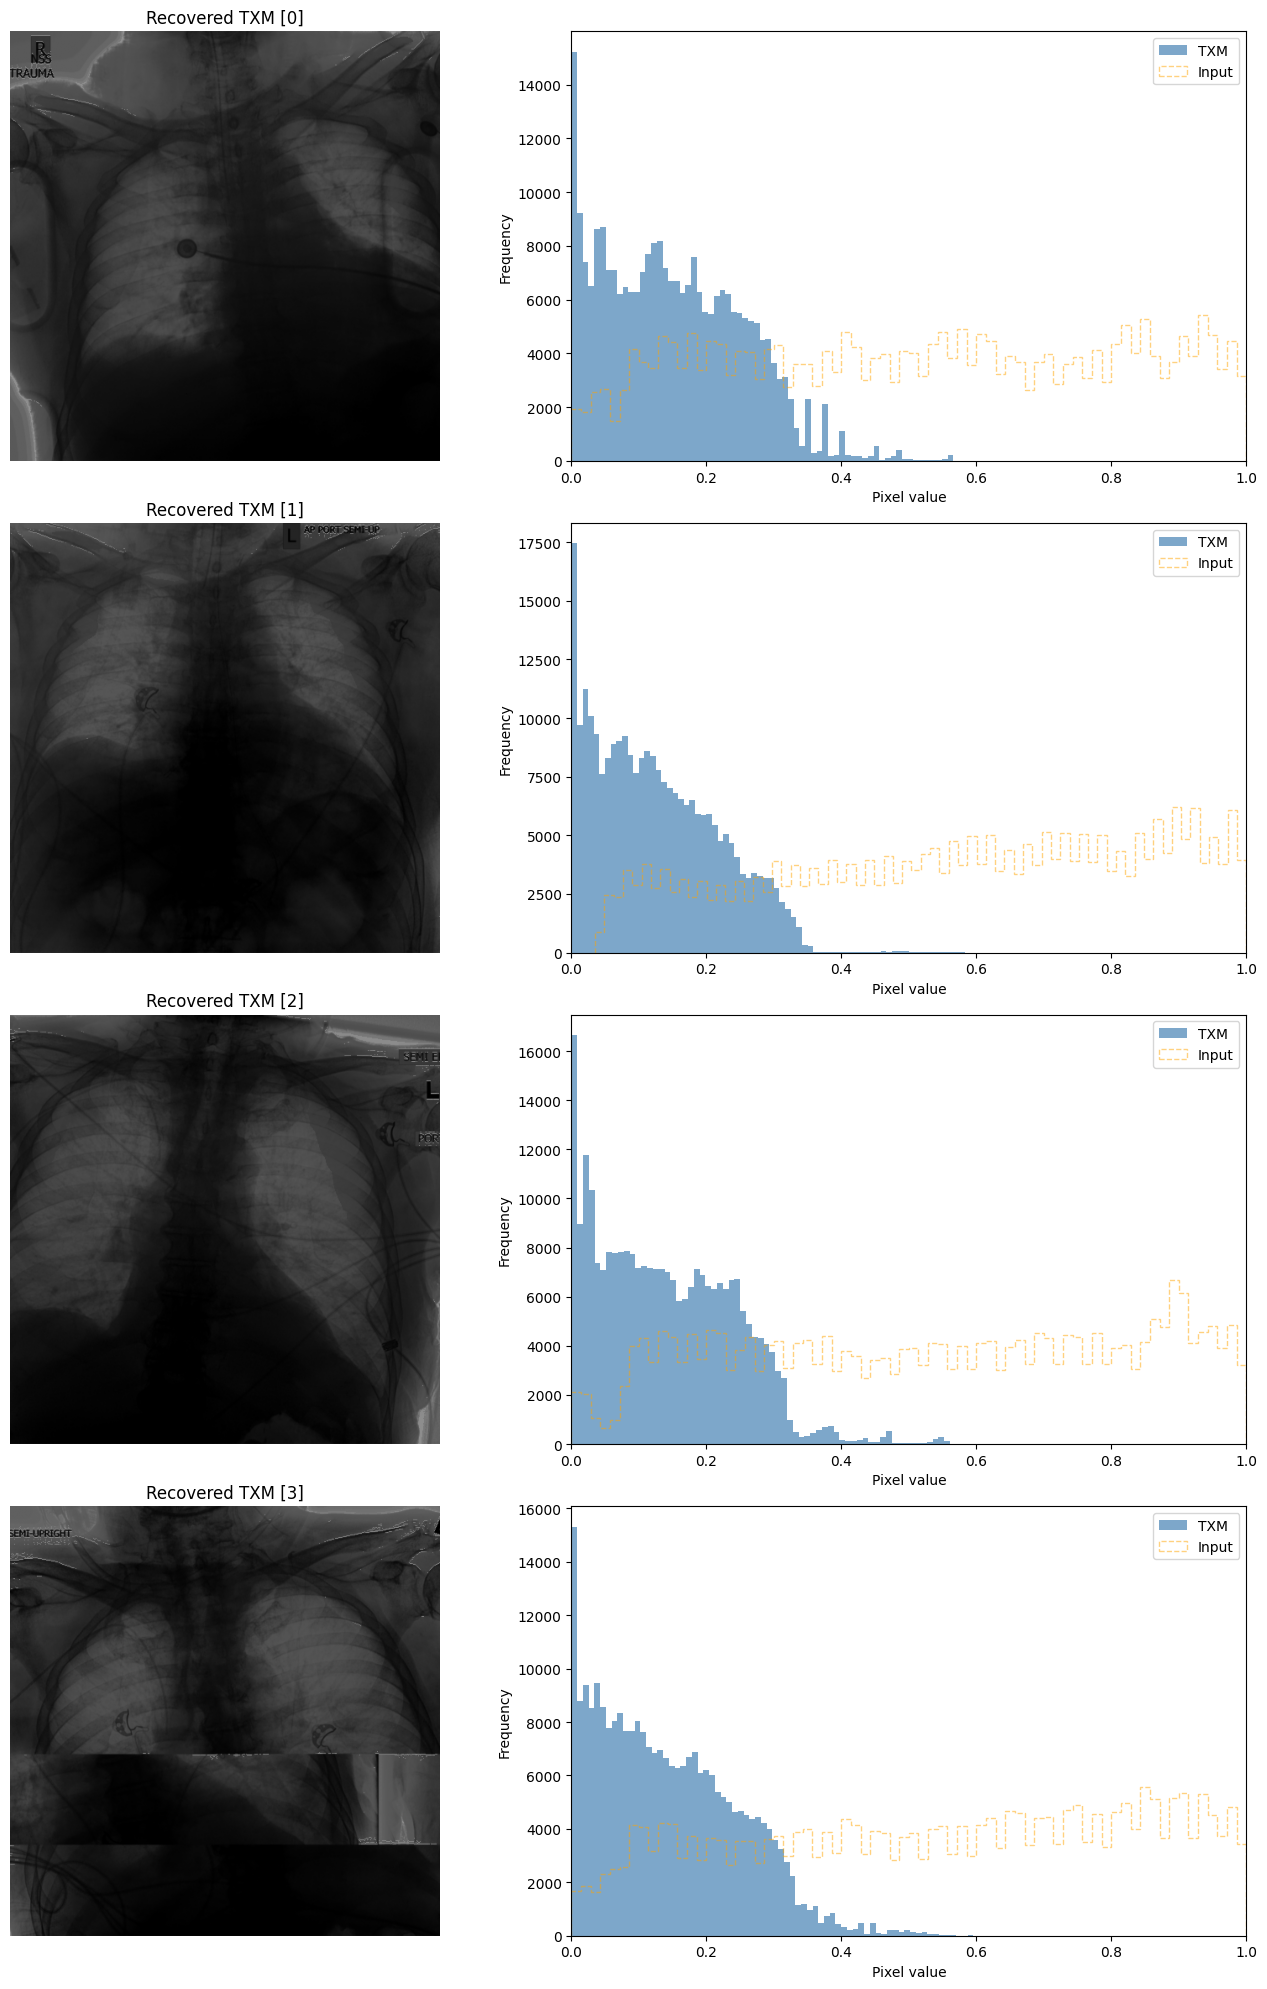

In [4]:
N_SHOW = 4
fig, axes = plt.subplots(N_SHOW, 2, figsize=(14, 5 * N_SHOW))

for i in range(N_SHOW):
    axes[i, 0].imshow(np.asarray(txm[i]), cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"Recovered TXM [{i}]")
    axes[i, 0].axis("off")

    axes[i, 1].hist(np.asarray(txm[i]).flatten(),  bins=70, alpha=0.7, label="TXM",   color="steelblue")
    axes[i, 1].hist(np.asarray(imgs[i]).flatten(), bins=70, alpha=0.5, label="Input",  color="orange", linestyle="--", histtype="step")
    axes[i, 1].set_xlim(0, 1)
    axes[i, 1].set_xlabel("Pixel value")
    axes[i, 1].set_ylabel("Frequency")
    axes[i, 1].legend()

fig.tight_layout()
fig.savefig("build/transmission_maps_histograms.png", bbox_inches="tight")
plt.show()